In [1]:
#import nbimporter
#import CLN
%run ./CLN.ipynb

class CLN_Cylinder_Hn(CLN):
    def __init__(self, mode='H', n_theta=1, a=0.01, sigma=1e6, mur=1):
        super().__init__(mode, a, sigma, mur)
        self.mode='H'
        self.C = CoordSys3D('C', transformation='cylindrical')
        self.x = sp.symbols('r', positive=True)
        self.y = sp.symbols('\\theta',real=True)
        
        self.sym_n=sp.symbols('n', positive=True, integer=True)

        if self.mode=='H': self.formulation=self.formulationH
        self.n_value=n_theta
        import scipy.special as sp_special
        self.namespace = {
                'besseli': lambda v, x: sp_special.iv(v, x),
                'sqrt': np.sqrt,
                'Pi': np.pi
            }
        self.subs_parameters={self.a: self.default_a,
                             self.sigma: self.default_sigma,
                             self.mu: self.default_mu,
                             self.sym_n: self.n_value}

    def We(self, E):
        
        return self.sigma * E**2
    def Wh(self,H):
        Ht=H[0]
        Hr=H[1]
        return self.mu * (Ht**2+Hr**2)
        
    def solveCurlCurl_A(self, Jz, Es, Hs=0):
        r=self.x
        a=self.a
        mu = self.mu
        Az = sp.Function('Az')(r)
        Ht = -sp.Derivative(Az, r)/mu
        Hr = - self.n_value/r*Az/mu
        curl_H=1/r*sp.Derivative(r*Ht, r) -self.n_value/r*Hr
        #curl_H=sp.Derivative(Ht, r) + Ht +-self.nt/r*Hr
        #curl_H=sp.Derivative(-sp.Derivative(Az, r), r) -sp.Derivative(Az, r)/r +self.nt**2/r**2 *Az 
        sol=sp.dsolve(sp.Eq(curl_H, Jz), Az).rhs
        sol=self.remove_divergence(sol, 0)
        eq_bc = sp.Eq(-sol.diff(r).subs(r, a)/mu, Hs)
        C2= sp.symbols('C2')
        sub = sp.solve([eq_bc], (C2))
        sol=sol.subs(sub)

        Ht=Ht.subs(Az, sol).doit().cancel()
        Hr=Hr.subs(Az, sol).doit().cancel()
        Az=sol
        #return [Hr, Ht, 0] , Az
        return np.array([Hr, Ht, 0]), Az

    def Vintegrate(self, integrand):
        r= self.x
        a = self.a
        return sp.integrate(integrand * r, (r, 0, a)) / a 
    """
    def calc_exact_Z(self, omega, a=None, sigma=None, mu=None):
        import scipy.special as sp_special
        #NumPy / SciPy による数値計算ルーチン。
        a_v = self.default_a if a is None else (float(a) if not hasattr(a, 'evalf') else float(a.evalf()))
        sigma_v = self.default_sigma if sigma is None else (float(sigma) if not hasattr(sigma, 'evalf') else float(sigma.evalf()))
        mu_v = self.default_mu if mu is None else (float(mu) if not hasattr(mu, 'evalf') else float(mu.evalf()))
        
        s_val = 1j * complex(omega)

        if self.f_exact_num is None:
            s_sym = sp.symbols('s', complex=True)
            a_sym, sigma_sym, mu_sym = sp.symbols('a sigma mu', positive=True)
            Z_sym = self.get_exact_Z_symbolic()
        
            namespace = {
                'besseli': lambda v, x: sp_special.iv(v, x),
                'sqrt': np.sqrt,
                'Pi': np.pi
            }
            self.f_exact_num = sp.lambdify((s_sym, a_sym, sigma_sym, mu_sym), Z_sym, modules=[namespace, 'numpy'])
        return self.f_exact_num(s_val, a_v, sigma_v, mu_v)
    """

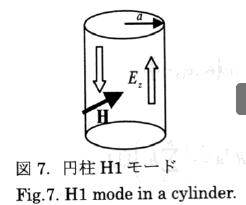

In [2]:
def formulationA(self, output=True):
    if output:
        display(Markdown("# ***** Hn mode in a cylinder *****"))

    r, a, s, sigma, mu, Es = self.x, self.a, self.s, self.sigma, self.mu, self.Es
    n=self.sym_n #sp.symbols('n', positive=True, integer=True)
    
    C = self.C
    
    #r = C.r  # 半径方向変数
    theta = C.theta  # 方位角方向変数
    z = C.z  # 軸方向変数
    theta = sp.symbols('theta', real=True)
    
    Az_c = sp.Function('Az')(C.r)
    
    A=Az_c*sp.cos(n*C.theta)*C.k
    B = sp.vector.curl(A)
    H=B/mu
    if output:
        display(Markdown("---"))
        display(Markdown("### **【ステップ 1】磁束密度 $\\mathbf{B}$ と磁界 $\\mathbf{H}$ の定義**"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{A}} = {sp.latex(A)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{B}} = \\nabla \\times \\mathbf{{A}} = {sp.latex(B)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{H}} = \\frac{{\\mathbf{{B}}}}{{\\mu}} = {sp.latex(H)} \\end{{equation}}"))

    curl_H = sp.vector.curl(H)
    if output:
        display(Markdown("---"))
        display(Markdown("### **【ステップ 2】磁界の回転 $\\nabla \\times \\mathbf{H}$ の展開**"))
        display(Markdown(f"\\begin{{equation}} \\nabla \\times \\mathbf{{H}} = {sp.latex(curl_H)} \\end{{equation}}"))

    Az_r = sp.Function('Az')(r)
    J=-sigma*s*Az_c*sp.cos(C.theta*n)*C.k
    
    eq=curl_H.dot(C.k)-J.dot(C.k)
    eq=eq/sp.cos(C.theta*n)*mu
    eq=eq.simplify()

    Az_r = sp.Function('Az')(r)
    eq=eq.subs(C.r,r)
    eq=eq.subs(C.r,r)
    eq=eq.subs(C.r, r).subs(Az_c.subs(C.r, r), Az_r)
    eq=sp.Eq(-eq, 0)
    
    if output:
        display(Markdown("---"))
        display(Markdown("### **【ステップ 4】支配方程式　**"))
        display(Markdown(f"\\begin{{equation}} {sp.latex(eq)} \\end{{equation}}"))

    As=-Es/s
    sol=sp.dsolve(eq,Az_r).rhs
    sol = sol.replace(lambda expr: expr.has(sp.bessely), lambda expr: 0)
    C1= sp.symbols('C1')
    sols = sp.solve(sp.Eq(sol.subs(r,a), As), (C1))
    sol = sol.subs(C1, sols[0])
    sol=sol.simplify()
    
    alpha_val = sp.sqrt(mu) * sp.sqrt(s) * sp.sqrt(sigma)
    k = sp.Symbol('k', positive=True)
    sol=sol.subs(alpha_val, k)
    Az=sol#*sp.cos(n*theta)
    Ez=-s*Az
   
    Hr=-n*Az/(r*mu)
    Ht=-sp.Derivative(Az, r)/mu
    Ht = Ht.cancel()
    Ht=Ht.together().simplify()
    Ht=Ht.doit()

    Z_expr = (Ez / Ht).subs(alpha_val, k).subs({r: a}).simplify()
    if output:
        display(Markdown("---"))
        display(Markdown("### **【ステップ 5】解析解（電場・磁界・表面インピーダンス）**"))
        display(Markdown(f"\\begin{{equation}} k = {sp.latex(alpha_val)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} E_z(r) = {sp.latex(Ez)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} H_\\theta(r) = {sp.latex(Ht)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} H_r(r) = {sp.latex(Hr)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} Z = {sp.latex(Z_expr)} \\end{{equation}}"))
    
    Z_exact_sym = Z_expr.subs(k, alpha_val).simplify()
    return Z_exact_sym


CLN_Cylinder_Hn.formulationH = formulationA

#cln=CLN_Cylinder_Hn('H')
#cln.formulation()


### 📊 現在のパラメータ設定
- **モード (`mode`)**: `H`
- **次数 ($n_\theta$)**: `1`
- **半径 (`a`)**: $a$ ( `0.01`)
- **導電率  ($\sigma$)**: ( `1000000.0`)
- **比透磁率 ($\mu_r$)**:   `1.00000000000000`)



# ***** Hn mode in a cylinder *****

---

### **【ステップ 1】磁束密度 $\mathbf{B}$ と磁界 $\mathbf{H}$ の定義**

\begin{equation} \mathbf{A} = \left(\operatorname{Az}{\left(\mathbf{{r}_{C}} \right)} \cos{\left(\mathbf{{theta}_{C}} n \right)}\right)\mathbf{\hat{k}_{C}} \end{equation}

\begin{equation} \mathbf{B} = \nabla \times \mathbf{A} = \left(- \frac{n \operatorname{Az}{\left(\mathbf{{r}_{C}} \right)} \sin{\left(\mathbf{{theta}_{C}} n \right)}}{\mathbf{{r}_{C}}}\right)\mathbf{\hat{i}_{C}} + \left(- \cos{\left(\mathbf{{theta}_{C}} n \right)} \frac{d}{d \mathbf{{r}_{C}}} \operatorname{Az}{\left(\mathbf{{r}_{C}} \right)}\right)\mathbf{\hat{j}_{C}} \end{equation}

... (31 outputs left out)

<IPython.core.display.Math object>

**【適用する置き換えの式】**

<IPython.core.display.Math object>

Eq(Z_{\text{CLN}}(s), 1/(1/(4*R_c + 1/(1/(8*R_c + 1/(1/(12*R_c + 1/(1/(L_c*s/18 + 16*R_c) + 14/(L_c*s))) + 10/(L_c*s))) + 6/(L_c*s))) + 1/(L_c*s)))

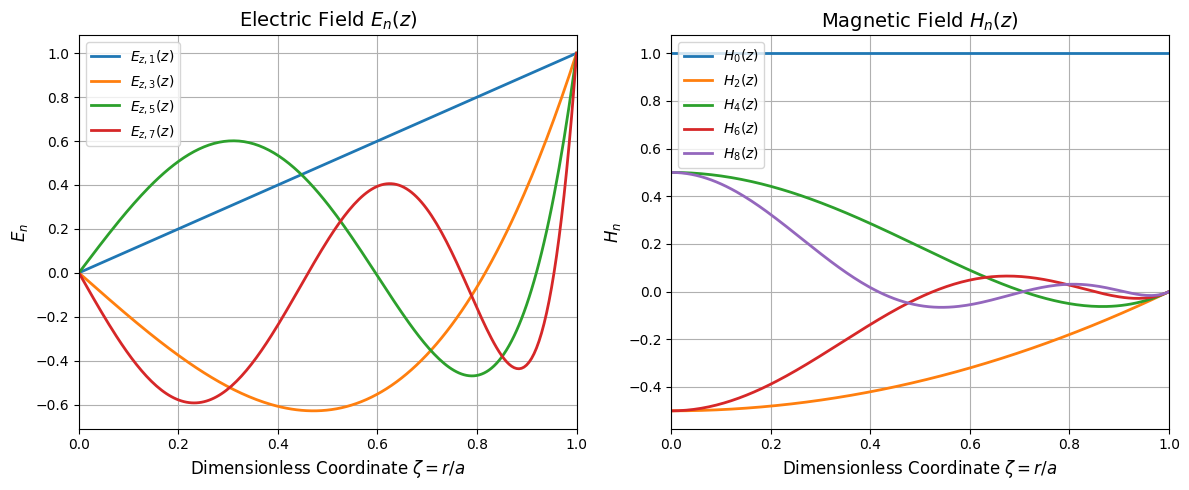

{a: 0.01, sigma: 1000000.0, mu: 4.0e-7*pi, n: 1}


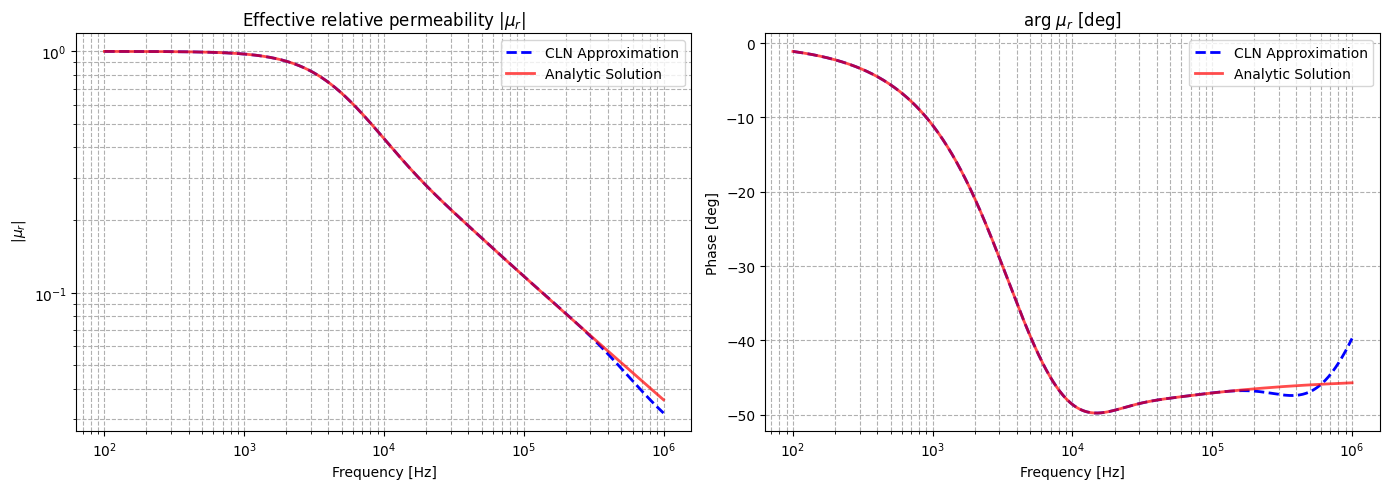

In [5]:
cln=CLN_Cylinder_Hn('H', 1)
cln.displayParameters()
R, L, A, E, H, Z=cln.buildCLN('A', nmax=8)
cln.formulationH()
cln.displayE(E)
cln.displayH(H)
cln.displayZ(Z)
cln.plot_EH(E, H)
freq_list = np.logspace(2, 6, 500)
cln.plot_Z(Z, freq_list)

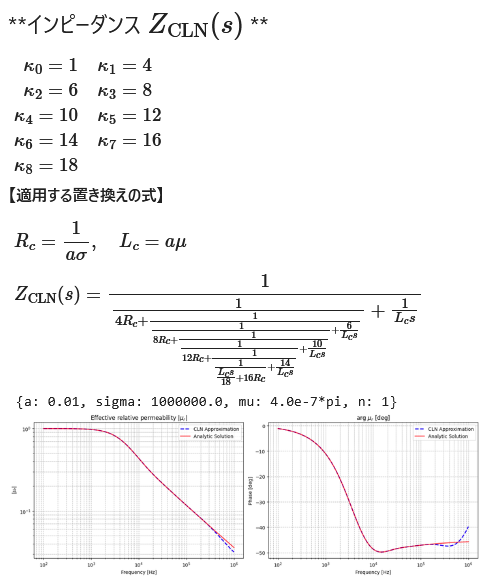

In [4]:
import sympy as sp
from IPython.display import display, Markdown, Math
from sympy.vector import CoordSys3D, curl, gradient

def test(self, output=True):
    r, a, s, sigma, mu, Es = self.x, self.a, self.s, self.sigma, self.mu, self.Es
    n=sp.symbols('n_\\theta', positive=True, integer=True)

    C = self.C
    
    #r = C.r  # 半径方向変数
    theta = C.theta  # 方位角方向変数
    z = C.z  # 軸方向変数
    #theta = sp.symbols('theta', real=True)

    Az=sp.Function('Az')(C.r)
    A=Az* sp.cos(n*theta)*C.k
    E=-sigma*A
    B=sp.vector.curl(A)
    H=B/mu
    curl_H=sp.vector.curl(H).simplify()
    if output:
        display(Markdown("---"))
        display(Markdown("### ** 磁場ベクトルポテンシャル$\\mathbf{{A}}$（z方向）とその回転　**"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{A}} = {sp.latex(A)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{E}} = {sp.latex(E)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{B}} = \\nabla \\times \\mathbf{{A}} = {sp.latex(B)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{H}} = \\frac{{\\mathbf{{B}}}}{{\\mu}} = {sp.latex(H)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\nabla \\times \\mathbf{{H}} = {sp.latex(curl_H)} \\end{{equation}}"))
    Tt=sp.Function('T_\\theta')(C.r)
    Tr=sp.Function('T_r')(C.r) 
    T=Tr* sp.sin(n*theta)*C.i + Tt* sp.cos(n*theta)*C.j
    H=T
    B=mu*T
    J=sp.vector.curl(T)    
    J=J.simplify()
    div_B=sp.vector.divergence(B)
    div_B=mu*((div_B/mu).simplify())
    eq_div_B=sp.Eq(div_B, 0)
    if output:
        display(Markdown("---"))
        display(Markdown("### ** 電流ベクトルポテンシャル$\\mathbf{{T}}$（$r, \\theta$ 方向）とその回転と発散 **"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{H}} = {sp.latex(H)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{B}} =  \\mu\\mathbf{{H}}= {sp.latex(B)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\mathbf{{J}} = \\nabla \\times \\mathbf{{T}} = {sp.latex(J)} \\end{{equation}}"))
        display(Markdown(f"\\begin{{equation}} \\nabla \\cdot \\mathbf{{B}} = {sp.latex(eq_div_B)} \\end{{equation}}"))

    div_eq=sp.Eq(div_B,0)
    Tt_sol = sp.solve(div_eq, Tt)[0]

    display(Markdown(f"\\begin{{equation}} {sp.latex(Tt)} = {sp.latex(Tt_sol)} \\end{{equation}}"))

    J_sub = J.subs(Tt, Tt_sol).doit().simplify()
    display(Markdown(f"\\begin{{equation}} \\mathbf{{J}}  = {sp.latex(J_sub)} \\end{{equation}}"))
    J_sub =(J_sub/sp.cos(n*theta)).simplify()


    
    
    # 1. 方程式の構築
    eq_Ampere = sp.Eq(J_sub.dot(C.k), 0)
    display(Markdown("### **元の式:**"))
    display(eq_Ampere)
    #sol_Ampere=sp.dsolve(eq_Ampere , Tr)
    #display(sol_Ampere)

    Tr_r = sp.Function('Tr')(r)
    Tt_r = sp.Function('Tr')(r)
    eq_Ampere = sp.Eq(
        sp.simplify(eq_Ampere.lhs).subs(C.r, r).subs(Tr.subs(C.r, r), Tr_r), 0)
    display(eq_Ampere)
    Hs = sp.Symbol('H_s', real=True)
    sol_Ampere=sp.dsolve(eq_Ampere)
    #sol_Ampere=sp.dsolve(eq_Ampere, ics={Tt_r.subs(r, a): Hs,Tt_r.subs(r, 0): 0}  )
    sol_Ampere=self.remove_divergence(sol_Ampere.rhs, 0)
    display(Markdown("### **原点での正則性を満たした解 (sol_regular):**"))
    #display(sp.Eq(Tt, sol_Ampere))
    #sol_Ampere=sol_Ampere.rhs
    sol_Ampere=sol_Ampere*Hs/sol_Ampere.subs(r, a)
    #zeta = sp.Symbol('\\zeta', real=True)

    Tt_r=Tt_sol.subs(C.r, r).subs(Tr.subs(C.r, r), sol_Ampere)
    Tt_r=Tt_r.doit().simplify()
    display(Tt_r)   

    #sol_Ampere=sol_Ampere.subs(r, a*zeta)
    sol_Ampere=sol_Ampere.simplify()
    display(sol_Ampere)
    
    """    
    # 分子を抽出した微分方程式
    numerator = eq_Ampere.lhs.as_numer_denom()[0]
    eq_ode = sp.Eq(numerator, 0)
    
    display(Markdown("### **微分方程式:**"))
    display(eq_ode)
    
    # 独立変数 r を明示して dsolve を実行する
    # sp.dsolve(eq, func, 独立変数) の形式で渡します
    sol_Ampere = sp.dsolve(eq_ode, Tt, r)
    
    display(Markdown("### **解 (sol_Ampere):**"))
    display(sol_Ampere)

    eq=sp.Eq(r*sp.Derivative(Tr, r) - n*Tt , -sp.Derivative(r**n*Tr, r)/r**(n-1)  )
    display(eq)
    eq=eq.doit().simplify()
    display(eq)
    #div_B= mu*(C.r*Derivative(Tr(C.r), C.r) - n_\theta*Tt(C.r) + Tr(C.r))*sin(C.theta*n_\theta)/C.r
    
    print('div_B=', div_B)
    div_B=div_B.simplify()
    div_eq=sp.Eq(div_B,0)
    display(div_eq)

    Hv=Bv/mu
    curl_H=sp.vector.curl(Hv)
    print('curl_H=', curl_H)
    Jz = sp.symbols('Jz', real=True)
    curl_H_z=(curl_H/sp.cos(n*C.theta)).dot(C.k)
    curl_H_z=curl_H_z.simplify()
    curl_eq=sp.Eq(curl_H_z ,Jz)
    display(curl_eq)
    #sol=sp.dsolve({div_eq, curl_eq}, {Bt, Br})
    #Disply(sol)

    Bt_expr = sp.solve(div_eq, Bt)[0]
    display('Bt_expr=', Bt_expr)

    # eq2 の Bt に代入
    eq2_substituted = curl_eq.subs(Bt, Bt_expr).doit()
    
    # 整頓して微分方程式にする
    eq2_simplified = sp.simplify(eq2_substituted)
    display(Markdown("### **代入・整理された単独の微分方程式:**"))
    display(eq2_simplified)

    # 3. Br(r) についての2階常微分方程式を解く
    #sol_Br = sp.dsolve(eq2_simplified, Br)
    #display(Markdown("### **Br(r) の解:**"))
    #display(sol_Br)

    # 独立変数 r を通常の Symbol として確実に定義
    r = sp.Symbol('r', positive=True)
    n = sp.symbols('n', positive=True, integer=True)
    
    # 従属変数
    Br = sp.Function('Br')(r)
    Bt = sp.Function('Bt')(r)

    # 1. 発散・回転の方程式を通常の r を使って再構築
    # （※ CoordSys3D の r と競合しないよう、必要に応じて置き換えてください）
    eq1 = sp.Eq(r * sp.diff(Br, r) - n * Bt + Br, 0)
    eq2 = sp.Eq((r * sp.diff(Bt, r) - n * Br + Bt) / (r * mu), Jz)

    # 2. eq1 から Bt を解いて eq2 に代入
    Bt_expr = sp.solve(eq1, Bt)[0]
    eq2_substituted = eq2.subs(Bt, Bt_expr).doit()
    eq2_simplified = sp.simplify(eq2_substituted)
    
    display(Markdown("### **代入・整理された単独の微分方程式:**"))
    display(eq2_simplified)

    # 3. Br(r) についての2階常微分方程式を解く（独立変数 r を明示）
    sol_Br = sp.dsolve(eq2_simplified, Br)
    display(Markdown("### **Br(r) の解:**"))
    display(sol_Br)
    print(sol_Br)

    Br_rhs = sol_Br.rhs
    for sym in Br_rhs.free_symbols:
        if 'C' in sym.name:
            # C1（または名前に 1 が含まれる定数）を 0 にする
            if '1' in sym.name:
                Br_rhs = Br_rhs.subs(sym, 0)    

    Br_sol_expr = Br_rhs

    display(Br_sol_expr)
    
    # sol_Bt を求めて整理する
    sol_Bt = Bt_expr.subs(Br, Br_sol_expr).doit()
    sol_Bt = sp.simplify(sol_Bt)
    
    display(Markdown("### **Bt(r) の解:**"))
    display(sp.Eq(Bt, sol_Bt))    
    
    # 1. sol_Br の右辺において、定数 C1 を 0 に置換
    # （※SymPyの解に含まれる定数名が C1, C2 である場合）
    #Br_c1_zero = sol_Br.rhs.subs(sp.Symbol('C1', real=True), 0)


                
    
    display(Markdown("### **C1 = 0 を代入した Br(r):**"))
    display(sp.Eq(Br, Br_c1_zero))

    # 2. 同様にして Bt(r) 側にも代入
    sol_Bt_c1_zero = Bt_expr.subs(Br, Br_c1_zero).doit()
    sol_Bt_c1_zero = sp.simplify(sol_Bt_c1_zero)
    
    display(Markdown("### **C1 = 0 を代入した Bt(r):**"))
    display(sp.Eq(Bt, sol_Bt_c1_zero))
    """
    
CLN_Cylinder_Hn.test = test

cln=CLN_Cylinder_Hn()
cln.test()   
    

---

### ** 磁場ベクトルポテンシャル$\mathbf{{A}}$（z方向）とその回転　**

\begin{equation} \mathbf{A} = \left(\operatorname{Az}{\left(\mathbf{{r}_{C}} \right)} \cos{\left(\mathbf{{theta}_{C}} n_{\theta} \right)}\right)\mathbf{\hat{k}_{C}} \end{equation}

\begin{equation} \mathbf{E} = \left(- \sigma \operatorname{Az}{\left(\mathbf{{r}_{C}} \right)} \cos{\left(\mathbf{{theta}_{C}} n_{\theta} \right)}\right)\mathbf{\hat{k}_{C}} \end{equation}

\begin{equation} \mathbf{B} = \nabla \times \mathbf{A} = \left(- \frac{n_{\theta} \operatorname{Az}{\left(\mathbf{{r}_{C}} \right)} \sin{\left(\mathbf{{theta}_{C}} n_{\theta} \right)}}{\mathbf{{r}_{C}}}\right)\mathbf{\hat{i}_{C}} + \left(- \cos{\left(\mathbf{{theta}_{C}} n_{\theta} \right)} \frac{d}{d \mathbf{{r}_{C}}} \operatorname{Az}{\left(\mathbf{{r}_{C}} \right)}\right)\mathbf{\hat{j}_{C}} \end{equation}

\begin{equation} \mathbf{H} = \frac{\mathbf{B}}{\mu} = \left(- \frac{n_{\theta} \operatorname{Az}{\left(\mathbf{{r}_{C}} \right)} \sin{\left(\mathbf{{theta}_{C}} n_{\theta} \right)}}{\mathbf{{r}_{C}} \mu}\right)\mathbf{\hat{i}_{C}} + \left(- \frac{\cos{\left(\mathbf{{theta}_{C}} n_{\theta} \right)} \frac{d}{d \mathbf{{r}_{C}}} \operatorname{Az}{\left(\mathbf{{r}_{C}} \right)}}{\mu}\right)\mathbf{\hat{j}_{C}} \end{equation}

... (11 outputs left out)

Eq((-n_\theta**2*Tr(r) + r**2*Derivative(Tr(r), (r, 2)) + 3*r*Derivative(Tr(r), r) + Tr(r))/(n_\theta*r), 0)

### **原点での正則性を満たした解 (sol_regular):**

H_s*a**(1 - n_\theta)*r**(n_\theta - 1)

H_s*a**(1 - n_\theta)*r**(n_\theta - 1)